<a href="https://colab.research.google.com/github/shadenaalghannam/Data_Mining_Project_Group2/blob/main/Python%20Notebook/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IT326: Data Mining Project – Group 2
## Water Potability: Classification and Clustering of Water Quality Data

---

### Contents
1. Problem
2. Data Mining Task
3. Data
4. Data Preprocessing
5. Data Mining Technique
6. Evaluation and Comparison
7. Findings and Discussion
8. References

# [1] Problem

Access to safe drinking water is essential for human health. Water that looks clear can still be unsafe to drink, because potability depends on several physical and chemical characteristics at the same time, such as pH, hardness, dissolved solids, disinfectant levels, chemical by-products of treatment and turbidity. Judging a sample means measuring all of these properties and comparing them against drinking-water standards, which takes time, laboratory resources and expert knowledge.

**What do we want to solve?**
This project aims to determine whether water is safe for human consumption. Using a dataset of water samples described by nine water-quality measurements, we want to:
- **Predict** whether a water sample is *potable* (safe to drink) or *non-potable*, based on its physical and chemical characteristics.
- **Discover** natural groups of water samples that share similar water-quality characteristics, and understand which attributes distinguish these groups.

**Why is it important?**
- **Public health:** unsafe drinking water can cause serious waterborne illnesses, so identifying unsafe water early helps reduce health risks.
- **Faster screening:** a model that flags potentially unsafe samples from routine measurements can help prioritize which samples need further laboratory testing.
- **Understanding the factors:** analyzing the data helps reveal which water-quality attributes are most related to potability, and which samples behave similarly, which can support decisions in water treatment and monitoring.

We chose this problem because water quality directly affects people's health and daily life, and the dataset gives us a real, measurable way to apply both classification and clustering techniques to it.

# [2] Data Mining Task

The problem is formalized as two data mining tasks:

### 2.1 Classification (supervised learning)
- **Goal:** predict the potability of a water sample.
- **Class label:** `Potability` – a binary attribute where **0 = Non-potable** and **1 = Potable** (binary classification).
- **Predictors:** the nine numeric water-quality attributes: `ph`, `Hardness`, `Solids`, `Chloramines`, `Sulfate`, `Conductivity`, `Organic_carbon`, `Trihalomethanes`, `Turbidity`.
- **Technique:** Decision Tree classification, built with two attribute selection measures – **Information Gain (Entropy)** and the **Gini index**.
- **Partitions:** three train/test splits – **90/10, 80/20 and 70/30**.
- **Evaluation:** accuracy and the confusion matrix for each measure and each partition.

### 2.2 Clustering (unsupervised learning)
- **Goal:** group water samples with similar water-quality characteristics and identify patterns in the data.
- **Input:** the same nine numeric attributes. The class label `Potability` is **removed** before clustering, because clustering must not use the class information.
- **Technique:** **K-means** clustering with three different numbers of clusters (**K = 2, 3, 4**).
- **Evaluation:** average **Silhouette coefficient**, total **within-cluster sum of squares (WCSS)** and the **Elbow method**, together with visualizations of the clusters.

| | Classification | Clustering |
|---|---|---|
| Learning type | Supervised | Unsupervised |
| Uses class label | Yes (`Potability` is the target) | No (`Potability` removed) |
| Algorithm | Decision Tree (Gini, Entropy) | K-means (K = 2, 3, 4) |
| Output | Potable / Non-potable for each sample | A cluster for each sample |
| Evaluation | Accuracy, confusion matrix | Silhouette, WCSS, Elbow method |

# [3] Data

## 3.1 Dataset Source
The dataset used in this project was obtained from **Kaggle** [2] under the title **"Water Quality and Potability"**.

URL: https://www.kaggle.com/datasets/uom190346a/water-quality-and-potability?resource=download

The data is provided as a CSV file and is stored unchanged in the repository as `Dataset/Raw_dataset.csv`.

## 3.2 Dataset Description
Each record is one water sample described by nine numeric water-quality measurements and one class label.

| # | Attribute | Description | Data type | Unit |
|---|---|---|---|---|
| 1 | `ph` | Acid–base balance of the water (scale 0–14); drinking water is normally between 6.5 and 8.5 | Numeric (float) | pH scale |
| 2 | `Hardness` | Amount of dissolved calcium and magnesium salts | Numeric (float) | mg/L |
| 3 | `Solids` | Total dissolved solids (TDS): minerals and salts dissolved in the water | Numeric (float) | ppm |
| 4 | `Chloramines` | Disinfectant formed when ammonia is added to chlorine during treatment | Numeric (float) | ppm |
| 5 | `Sulfate` | Concentration of dissolved sulfate | Numeric (float) | mg/L |
| 6 | `Conductivity` | Electrical conductivity, which reflects the amount of dissolved ions | Numeric (float) | μS/cm |
| 7 | `Organic_carbon` | Total organic carbon from decaying organic matter | Numeric (float) | ppm |
| 8 | `Trihalomethanes` | Chemical by-products that can form in chlorine-treated water | Numeric (float) | μg/L |
| 9 | `Turbidity` | Cloudiness of the water caused by suspended particles | Numeric (float) | NTU |
| 10 | `Potability` | **Class label**: 0 = Non-potable, 1 = Potable | Binary (int) | – |

The code cells below load the raw dataset and print its general information: number of records and attributes, data types, the class attribute and its values, the number of instances in each class, and a sample of the raw data.

### 3.2.1 Loading the Raw Dataset

In [ ]:
import pandas as pd
df = pd.read_csv("Raw_dataset.csv")

### 3.2.2 Number of Records and Attributes

In [ ]:
print("Number of records:", df.shape[0])
print("Number of attributes:", df.shape[1])

Number of records: 3276
Number of attributes: 10


### 3.2.3 Attribute Names and Data Types

In [ ]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']


In [ ]:
print("\nAttributes and Data Types:")
print(df.dtypes)


Attributes and Data Types:
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object


### 3.2.4 Class Attribute, Number of Classes and Instances per Class

In [ ]:
print("\nClass Attribute: Potability")
print("Class Values: 0 = Non-potable, 1 = Potable")


Class Attribute: Potability
Class Values: 0 = Non-potable, 1 = Potable


In [ ]:
print("\nNumber of Classes:", df["Potability"].nunique())


Number of Classes: 2


In [ ]:
print("\nNumber of Instances for Each Class:")
print(df["Potability"].value_counts())


Number of Instances for Each Class:
Potability
0    1998
1    1278
Name: count, dtype: int64


### 3.2.5 Sample of the Raw Dataset

In [ ]:
print("\nSample of the Raw Dataset:")
display(df.head())


Sample of the Raw Dataset:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


**Summary:**
The dataset contains 3,276 records and 10 attributes: nine numeric water-quality attributes and one class attribute (Potability). There are 1,998 non-potable samples (≈ 61%) and 1,278 potable samples (≈ 39%), so the classes are slightly imbalanced. The sample also shows some NaN values (e.g. in ph and Sulfate), which means the dataset contains missing values that we analyze in the next section.


## 3.3 Data Analysis
In this part, we apply summarization and visualization techniques to understand the main characteristics of the dataset and to identify data-quality issues (missing values, outliers, different scales) that decide which preprocessing steps are needed in Section [4].

### 3.3.1 Five-Number Summary

The five-number summary describes the distribution of the numerical attributes using the minimum, Q1, median, Q3, and maximum.

In [ ]:
numerical_data = df.drop("Potability", axis=1)
five_number_summary = pd.DataFrame({
    "Minimum": numerical_data.min(),
    "Q1": numerical_data.quantile(0.25),
    "Median": numerical_data.quantile(0.50),
    "Q3": numerical_data.quantile(0.75),
    "Maximum": numerical_data.max()})
five_number_summary.round(2)

,Minimum,Q1,Median,Q3,Maximum
ph,0.00,6.09,7.04,8.06,14.00
Hardness,47.43,176.85,196.97,216.67,323.12
Solids,320.94,15666.69,20927.83,27332.76,61227.20
Chloramines,0.35,6.13,7.13,8.11,13.13
Sulfate,129.00,307.70,333.07,359.95,481.03
Conductivity,181.48,365.73,421.88,481.79,753.34
Organic_carbon,2.20,12.07,14.22,16.56,28.30
Trihalomethanes,0.74,55.84,66.62,77.34,124.00
Turbidity,1.45,3.44,3.96,4.50,6.74


**Interpretation:**
The attributes have very different ranges. For example, Solids ranges from 320.94 to 61,227.20, while Chloramines ranges from 0.35 to 13.13, so the data needs to be normalized. The pH values reach 0 and 14, which are unrealistic for water samples and suggest outliers. Solids also has a much larger gap between Q3 and the maximum, which indicates a right-skewed distribution.


### 3.3.2 Outlier Detection

Outliers are identified using the IQR method. Values below the lower bound (Q1 − 1.5 × IQR) or above the upper bound (Q3 + 1.5 × IQR) are considered potential outliers.

In [ ]:
for column in numerical_data.columns:
    Q1 = numerical_data[column].quantile(0.25)
    Q3 = numerical_data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    lower_outliers = numerical_data[column][
        numerical_data[column] < lower_bound ]

    upper_outliers = numerical_data[column][
        numerical_data[column] > upper_bound ]

    print("Attribute:", column)
    print("Lower Outliers:")
    if len(lower_outliers)== 0:
        print("None")
    else:
        print(lower_outliers.to_string(index=False))

    print("Upper Outliers:")
    if len(upper_outliers) ==0:
        print("None")
    else:
        print(upper_outliers.to_string(index=False))

    print("Total Number of Outliers:",
          len(lower_outliers) + len(upper_outliers))
    print("-"* 50)

Attribute: ph
Lower Outliers:
1.844538
2.612036
2.798549
1.757037
0.227499
0.989912
2.690831
2.569244
2.803563
2.558103
2.974429
2.538116
2.945469
2.376768
1.431782
0.975578
2.925174
3.102076
0.000000
2.128531
1.985383
Upper Outliers:
11.180284
11.180695
11.267828
13.175402
11.301794
11.898078
11.027880
11.244507
12.246928
11.534880
14.000000
11.568768
11.235426
11.069456
11.219135
11.907740
13.541240
13.349889
11.563169
11.496702
11.496859
11.621140
11.390543
11.449739
11.491011
Total Number of Outliers: 46
--------------------------------------------------
Attribute: Hardness
Lower Outliers:
100.457615
103.464759
116.299330
104.752425
112.299485
105.859264
112.820254
103.173587
 98.771644
 47.432000
 81.710895
113.831112
 77.459586
 94.091307
 73.492234
108.699077
106.380113
 97.280909
 98.452931
116.061950
107.383327
116.725122
113.504698
115.392979
117.057314
110.865788
108.916629
100.806520
107.341982
111.246412
116.905479
116.338278
113.024472
111.478582
113.175965
114.463900
111

**Interpretation:**
All nine attributes contain outliers (366 values in total), with the most in Hardness (83) and Chloramines (61). Solids has outliers only on the upper side. Since these values are spread across many rows, removing them would lose a lot of data, so we decided to cap them instead (Section 4.2).


### 3.3.3 Boxplots

Boxplots provide another visual method for identifying potential outliers and showing the distribution of numerical attributes.

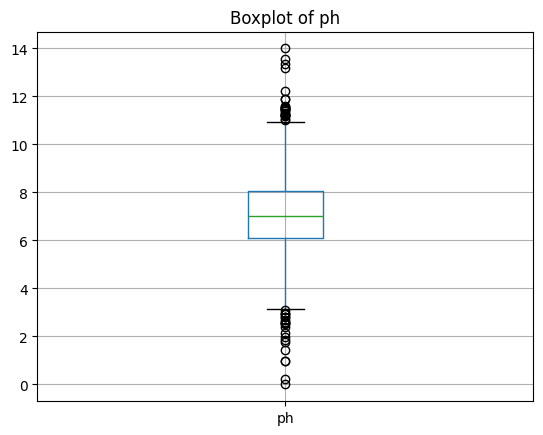

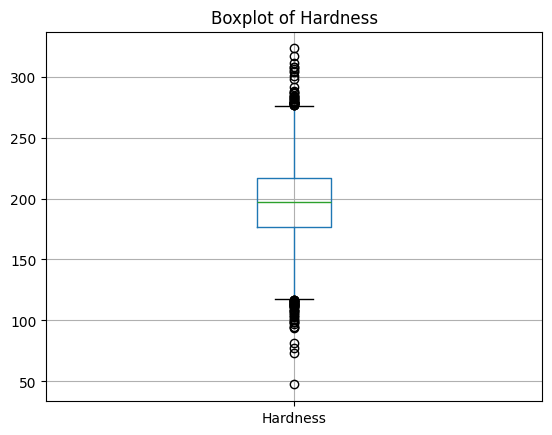

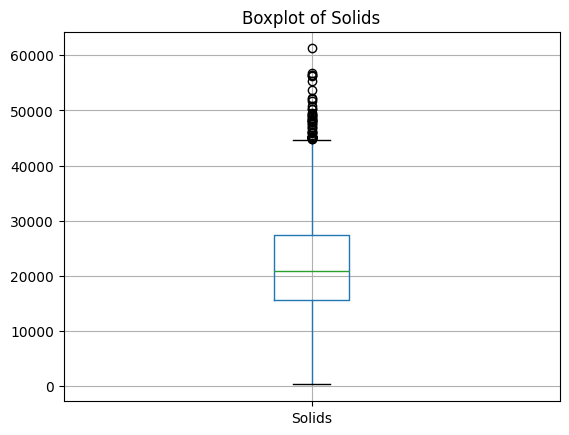

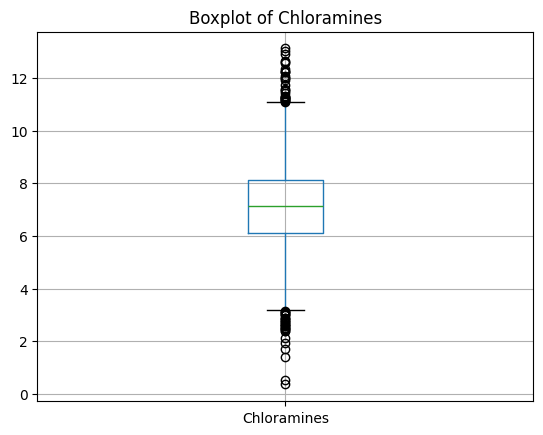

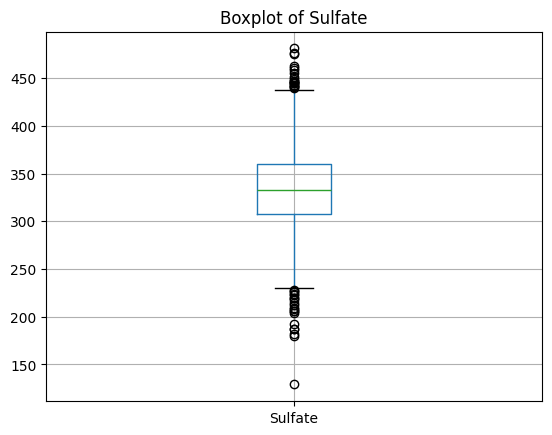

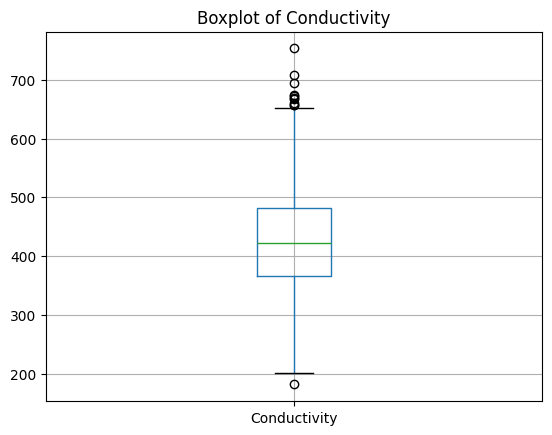

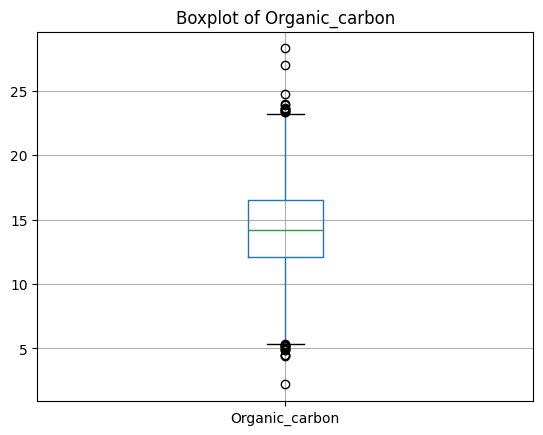

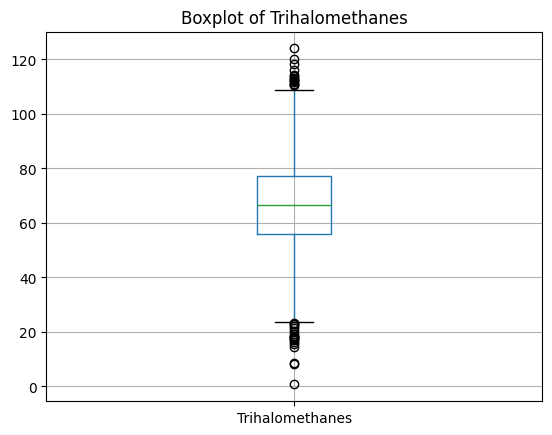

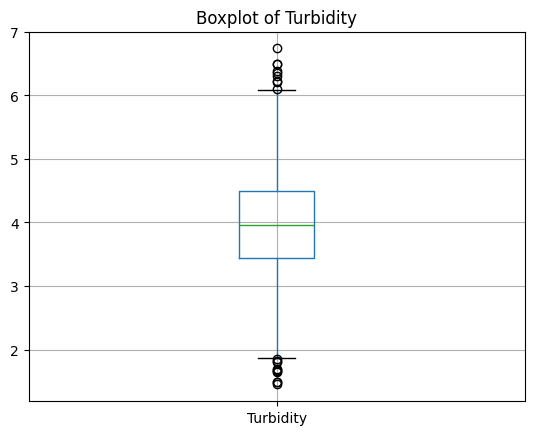

In [ ]:
import matplotlib.pyplot as plt
for column in numerical_data.columns:
    numerical_data[[column]].boxplot()
    plt.title("Boxplot of "+column)
    plt.show()

**Interpretation:**
The boxplots confirm the IQR results, as all attributes have points outside the whiskers. Most attributes have outliers on both sides, while Solids has them only above the upper whisker. The plots also show that each attribute has a different range of values, which supports applying outlier treatment and normalization.


### 3.3.4 Scatter Plot

A scatter plot is used to visualize the relationship between two numerical attributes.

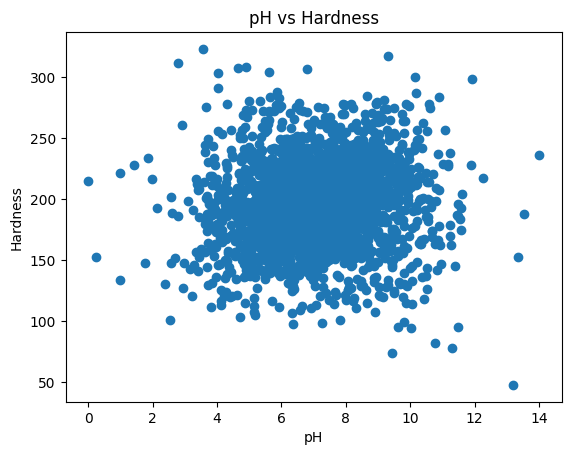

In [ ]:
plt.scatter(numerical_data["ph"],numerical_data["Hardness"])
plt.xlabel("pH")
plt.ylabel("Hardness")
plt.title("pH vs Hardness")
plt.show()

**Interpretation:**
The points are widely scattered, showing no clear relationship between pH and Hardness. Some points, such as pH values near 0 or 14, are far from the main group and indicate outliers that should be handled during preprocessing.


### 3.3.5 Histograms

Histograms are used to show the distribution of each numerical attribute.

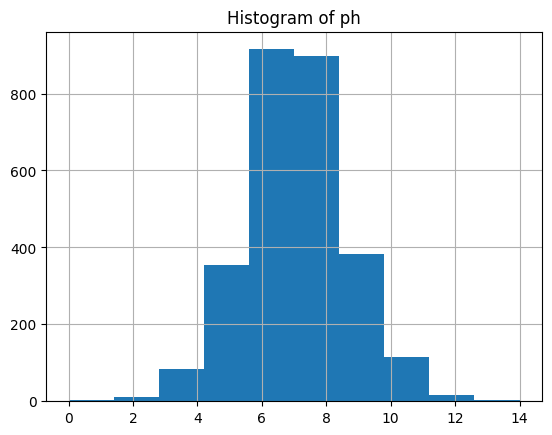

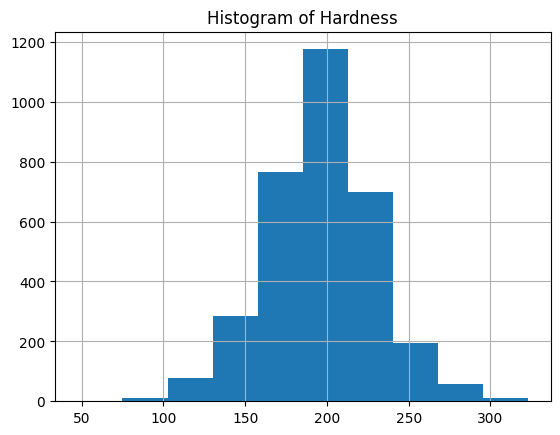

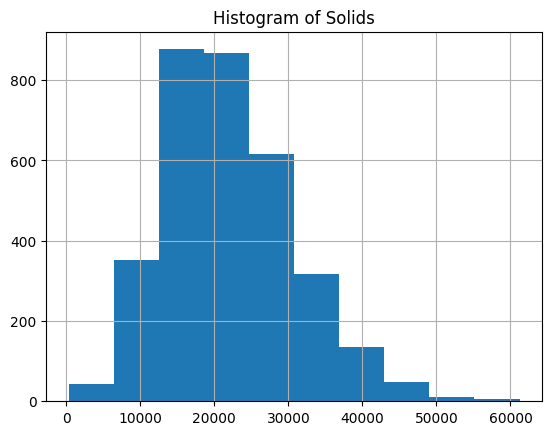

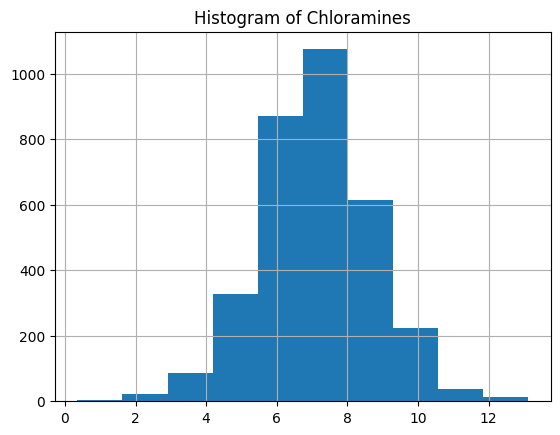

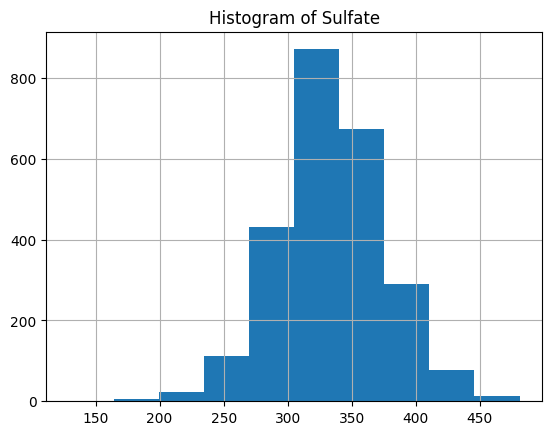

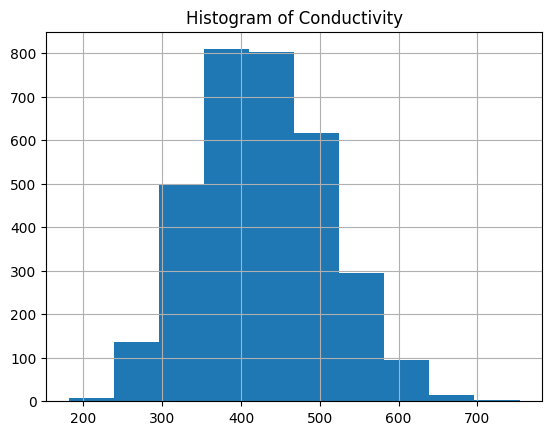

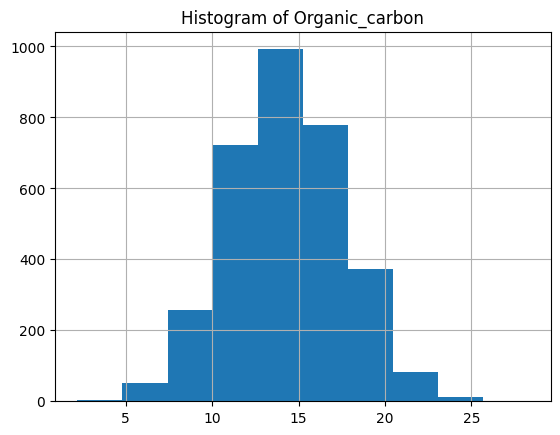

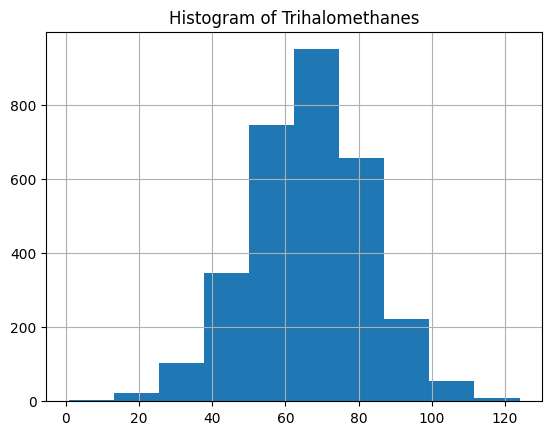

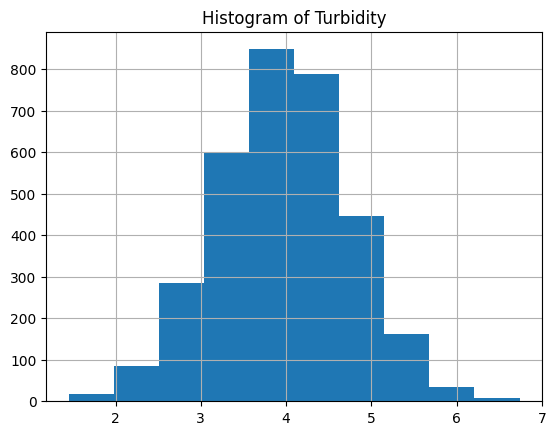

In [ ]:
for column in numerical_data.columns:
    numerical_data[[column]].hist()
    plt.title("Histogram of " + column)
    plt.show()

**Interpretation:**
Most attributes have a roughly normal distribution, where the mean and median are very close (e.g. pH: 7.08 vs 7.04), while Solids is skewed to the right. This showed us that the mean is a suitable value for filling missing values. The different ranges also show that the data needs to be scaled.


### 3.3.6 Bar Plot – Class Label Distribution

A bar plot is used to show the distribution of the class label (Potability), where 0 means not potable and 1 means potable.

Potability
0    1998
1    1278
Name: count, dtype: int64


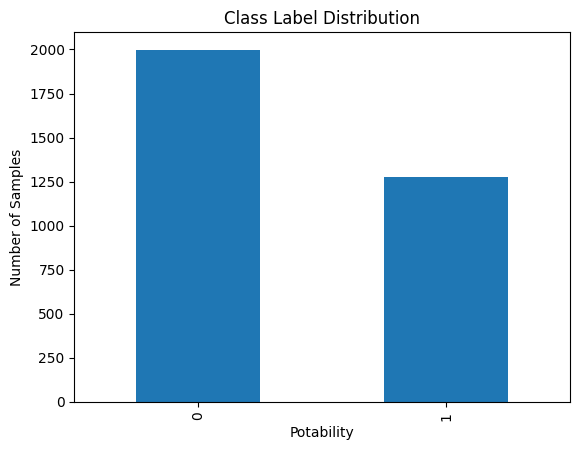

In [ ]:
class_counts = df["Potability"].value_counts()
print(class_counts)

class_counts.plot(kind="bar")
plt.xlabel("Potability")
plt.ylabel("Number of Samples")
plt.title("Class Label Distribution")
plt.show()

**Interpretation:**
The dataset contains more non-potable samples (1,998 ≈ 61%) than potable samples (1,278 ≈ 39%), indicating some class imbalance. This means an accuracy around 61% would be close to always predicting the majority class, so this should be considered when evaluating the models.


### 3.3.7 Missing Values

Missing values are checked for each attribute to find incomplete data.

In [ ]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)})
missing_values

,Missing Count,Missing Percentage
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00
Potability,0,0.00


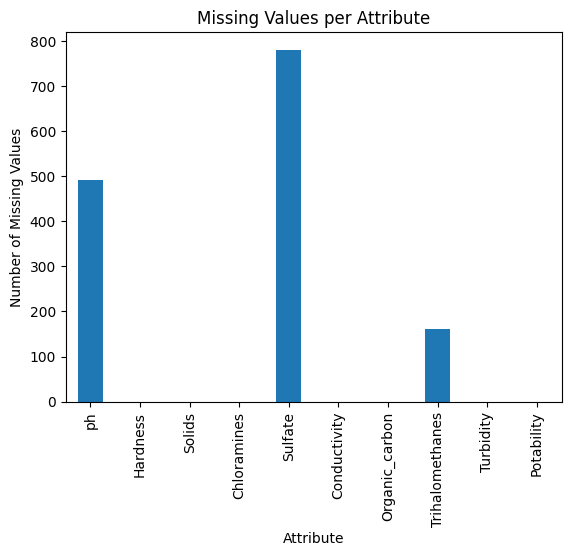

In [ ]:
missing_values["Missing Count"].plot(kind="bar")
plt.xlabel("Attribute")
plt.ylabel("Number of Missing Values")
plt.title("Missing Values per Attribute")
plt.show()

**Interpretation:**
Three attributes contain missing values: Sulfate (781, 23.84%), ph (491, 14.99%) and Trihalomethanes (162, 4.95%). About 38.6% of the records have at least one missing value, so deleting them would lose a large part of the data. Therefore, we filled the missing values with the mean of each attribute (Section 4.1).


### 3.3.8 Statistical Summary

The statistical summary shows the count, mean, standard deviation, minimum, quartiles and maximum of each numerical attribute.

In [ ]:
numerical_data.describe().round(2)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
count,2785.00,3276.00,3276.00,3276.00,2495.00,3276.00,3276.00,3114.00,3276.00
mean,7.08,196.37,22014.09,7.12,333.78,426.21,14.28,66.40,3.97
std,1.59,32.88,8768.57,1.58,41.42,80.82,3.31,16.18,0.78
min,0.00,47.43,320.94,0.35,129.00,181.48,2.20,0.74,1.45
25%,6.09,176.85,15666.69,6.13,307.70,365.73,12.07,55.84,3.44
50%,7.04,196.97,20927.83,7.13,333.07,421.88,14.22,66.62,3.96
75%,8.06,216.67,27332.76,8.11,359.95,481.79,16.56,77.34,4.50
max,14.00,323.12,61227.20,13.13,481.03,753.34,28.30,124.00,6.74


**Interpretation:**
The count values show that ph, Sulfate and Trihalomethanes have fewer values than the other attributes, which confirms the missing values. The attributes also have very different standard deviations (e.g. Solids ≈ 8,768.57 vs Turbidity ≈ 0.78), which shows that the data should be scaled.

### 3.3.9 Summary of the Data Analysis
Based on the analysis, the dataset needs preprocessing because of:
- **Missing values** in ph, Sulfate and Trihalomethanes → handled by mean imputation.
- **Outliers** in all numeric attributes → handled by IQR capping.
- **Different scales** between attributes → handled by Z-score normalization.

The class imbalance is not changed, but it is considered when evaluating the models.


# [4] Data Preprocessing
Based on the data analysis, we applied three preprocessing techniques:
1. **Handling missing values:** filled the missing values in ph, Sulfate and Trihalomethanes with the mean of each attribute.
2. **Handling outliers:** capped the outliers in all numeric attributes using the IQR method.
3. **Normalization:** applied Z-score normalization to all numeric attributes.

No attributes or records were removed, and the Potability class attribute was not changed. The raw dataset was kept unchanged, and the preprocessed data was saved separately as Preprocessed_dataset.csv.


## 4.1 Handling Missing Values
The dataset contains missing values in some numerical attributes. The missing values are replaced with the mean value of each numerical attribute.

In [ ]:
print("Missing values before preprocessing:")
print(df.isna().sum())

column_means = df.mean(numeric_only=True)
df = df.fillna(column_means)

print("\nMissing values after preprocessing:")
print(df.isna().sum())

Missing values before preprocessing:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Missing values after preprocessing:
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


**Result:** The missing values were successfully replaced with the mean values of their corresponding numerical attributes. After preprocessing, the dataset contains **no missing values**, and all 3,276 records were kept.

## 4.2 Handling Outliers
The dataset contains outliers in some numerical attributes. The outliers are identified using the IQR method and treated by capping their values at the calculated lower and upper bounds.

**Step 1:** count the outliers in each attribute before capping.

In [ ]:
numeric_columns = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
                   'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) |
                  (df[column] > upper_bound)]

    print(column, ":", len(outliers), "outliers")

ph : 142 outliers
Hardness : 83 outliers
Solids : 47 outliers
Chloramines : 61 outliers
Sulfate : 264 outliers
Conductivity : 11 outliers
Organic_carbon : 25 outliers
Trihalomethanes : 54 outliers
Turbidity : 19 outliers


The number of outliers increased for ph, Sulfate and Trihalomethanes after filling the missing values, because many values became equal to the mean, which made the IQR smaller.

**Step 2:** cap the values of each attribute at its lower and upper bounds.


In [ ]:
for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) |
                    (df[column] > upper_bound)]
    df[column] = df[column].clip(lower = lower_bound, upper = upper_bound)

**Step 3:** count the outliers again after capping.

In [ ]:
for column in numeric_columns:
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

  print(column, ":", len(outliers), "outliers")

ph : 0 outliers
Hardness : 0 outliers
Solids : 0 outliers
Chloramines : 0 outliers
Sulfate : 0 outliers
Conductivity : 0 outliers
Organic_carbon : 0 outliers
Trihalomethanes : 0 outliers
Turbidity : 0 outliers


**Result:** After IQR-based capping, no outliers remained outside the calculated bounds, showing that the extreme values were successfully limited. Unrealistic values such as pH = 0 or 14 are now replaced by the nearest acceptable bound, while the number of records stays the same.

## 4.3 Normalization
The numerical attributes have different scales. Z-score normalization is applied using `StandardScaler` to make the numerical features comparable:

$$z = \frac{x - \mu}{\sigma}$$

The `Potability` class attribute is excluded because it represents the class label.

In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_columns = df.columns.drop("Potability")

scaler = StandardScaler()
df[numeric_columns] = scaler.fit_transform(df[numeric_columns])

df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0.000612,0.265461,-0.135691,0.115564,1.093335,1.715401,-1.187299,1.328436,-1.292657,0
1,-2.309292,-2.091993,-0.387249,-0.315144,-0.000406,2.070162,0.272685,-0.651695,0.687944,0
2,0.737603,0.869786,-0.238325,1.395235,-0.000406,-0.093403,0.786278,-0.000022,-1.173116,0
3,0.895116,0.561689,0.007136,0.607257,0.727178,-0.780410,1.263149,2.190618,0.852978,0
4,1.456334,-0.477657,-0.463030,-0.372561,-0.744666,-0.344116,-0.828861,-2.222985,0.139720,0


**Result:** All numeric attributes now have a mean of about 0 and a standard deviation of about 1, while Potability stayed unchanged. This step is mainly important for K-means because it is based on distances.


## 4.4 Comparison between the Raw and Preprocessed Datasets
The raw and preprocessed datasets were compared based on their dimensions, missing values, and descriptive statistics. The comparison demonstrates the changes resulting from the missing value handling, outlier treatment, and normalization steps applied during preprocessing.

In [ ]:
raw_data = pd.read_csv("Raw_dataset.csv")

print("Raw dataset shape: " , raw_data.shape)
print("Cleaned dataset shape: " , df.shape)

Raw dataset shape:  (3276, 10)
Cleaned dataset shape:  (3276, 10)


The raw and cleaned datasets have the same dimensions, indicating that no rows or attributes were removed during preprocessing.

In [ ]:
print("Missing values in the raw dataset: ")
print(raw_data.isnull().sum())
print("\nMissing values in the cleaned dataset: ")
print(df.isnull().sum())

Missing values in the raw dataset: 
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Missing values in the cleaned dataset: 
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


The raw dataset contains missing values in Sulfate, pH, and Trihalomethanes, while the cleaned dataset contains no missing values after mean imputation.

In [ ]:
print("Raw dataset statistics: ")
display(raw_data.describe())
print("\nCleaned dataset statistics: ")
display(df.describe())

Raw dataset statistics: 


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000



Cleaned dataset statistics: 


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,3.276000e+03,3.276000e+03,3.276000e+03,3.276000e+03,3.276000e+03,3.276000e+03,3.276000e+03,3.276000e+03,3.276000e+03,3276.000000
mean,-5.612116e-16,-1.507409e-16,-2.271958e-16,-2.776235e-16,-2.056149e-15,-9.353527e-16,1.735147e-17,-1.301360e-16,-7.157482e-17,0.390110
std,1.000153e+00,1.000153e+00,1.000153e+00,1.000153e+00,1.000153e+00,1.000153e+00,1.000153e+00,1.000153e+00,1.000153e+00,0.487849
min,-2.309292e+00,-2.476150e+00,-2.518320e+00,-2.575035e+00,-2.097736e+00,-2.910950e+00,-2.723785e+00,-2.570343e+00,-2.728123e+00,0.000000
25%,-5.806274e-01,-6.104492e-01,-7.321673e-01,-6.440698e-01,-5.255788e-01,-7.497725e-01,-6.744986e-01,-6.311210e-01,-6.787427e-01,0.000000
50%,6.121225e-04,1.796822e-02,-1.198018e-01,5.508795e-03,-4.061619e-04,-5.269904e-02,-1.980727e-02,-1.558567e-03,-1.492293e-02,0.000000
75%,5.718160e-01,6.333513e-01,6.256933e-01,6.432406e-01,5.225261e-01,6.910125e-01,6.916921e-01,6.616937e-01,6.875106e-01,1.000000
max,2.300481e+00,2.499052e+00,2.662484e+00,2.574206e+00,2.094683e+00,2.852190e+00,2.740978e+00,2.600916e+00,2.736891e+00,1.000000


The statistics show that after outlier capping and normalization, all attributes have the same count (3,276), a mean close to 0 and a standard deviation close to 1, while the Potability class attribute remains unchanged.


## 4.5 Save the Preprocessed Dataset
The preprocessed data is saved separately as `Preprocessed_dataset.csv`, while the raw dataset file stays unchanged.

In [ ]:
df.to_csv("Preprocessed_dataset.csv", index=False)

## 4.6 Data Snapshots

**Snapshot of the raw data**

In [ ]:
raw_data.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


**Snapshot of the preprocessed data**

In [ ]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0.000612,0.265461,-0.135691,0.115564,1.093335,1.715401,-1.187299,1.328436,-1.292657,0
1,-2.309292,-2.091993,-0.387249,-0.315144,-0.000406,2.070162,0.272685,-0.651695,0.687944,0
2,0.737603,0.869786,-0.238325,1.395235,-0.000406,-0.093403,0.786278,-0.000022,-1.173116,0
3,0.895116,0.561689,0.007136,0.607257,0.727178,-0.780410,1.263149,2.190618,0.852978,0
4,1.456334,-0.477657,-0.463030,-0.372561,-0.744666,-0.344116,-0.828861,-2.222985,0.139720,0


## 4.7 Summary of the Preprocessing Results
After preprocessing, the dataset still has 3,276 records and 10 attributes, with no missing values and no outliers, and all numeric attributes are on the same scale. The class distribution stayed the same (1,998 non-potable and 1,278 potable), so the dataset is ready for classification and clustering.


# [5] Data Mining Technique

Two data mining techniques are applied to the preprocessed dataset: classification and clustering. Both are implemented in Python using the scikit-learn library [3]. <br>

For classification, we chose the Decision Tree because it is easy to understand and shows which attributes determine whether the water is safe to drink. We applied it with two attribute selection measures, Gini and Entropy, and tested each with three train/test partitions: 90/10, 80/20 and 70/30. The methods used are DecisionTreeClassifier, train_test_split, accuracy_score, confusion_matrix and plot_tree. <br>

For clustering, we chose K-means because it groups similar samples without using the class label, so the `Potability` attribute is removed before clustering. We applied it with K = 2, 3 and 4, and evaluated the results with the Silhouette score and the Elbow method. The methods used are KMeans, silhouette_score, inertia_ and PCA, which reduces the nine attributes to two dimensions so the clusters can be plotted.

### 5.1 Required Libraries

In [ ]:
#Import required libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

### 5.2 Loading the Preprocessed Dataset

In [ ]:
#Load the preprocessed dataset
df= pd.read_csv("Preprocessed_dataset.csv")

#Display the first five rows
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0.000612,0.265461,-0.135691,0.115564,1.093335,1.715401,-1.187299,1.328436,-1.292657,0
1,-2.309292,-2.091993,-0.387249,-0.315144,-0.000406,2.070162,0.272685,-0.651695,0.687944,0
2,0.737603,0.869786,-0.238325,1.395235,-0.000406,-0.093403,0.786278,-0.000022,-1.173116,0
3,0.895116,0.561689,0.007136,0.607257,0.727178,-0.780410,1.263149,2.190618,0.852978,0
4,1.456334,-0.477657,-0.463030,-0.372561,-0.744666,-0.344116,-0.828861,-2.222985,0.139720,0


### 5.3 Separating the Features and the Class Label

In [ ]:
#Separate features and target variable
X= df.drop("Potability", axis=1)
y= df["Potability"]

#Display the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3276, 9)
Target shape: (3276,)


# [6] Evaluation and Comparison
## 6.1 Classification
### 6.1.1 Decision Tree using Gini Index

### Gini Decision Tree - 70/30 Partition

In [ ]:
#Split the data: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

#Create the Gini Decision Tree
model= DecisionTreeClassifier(
    criterion="gini", random_state=42)

#Train the model
model.fit(X_train, y_train)

#Predict the test data
y_pred= model.predict(X_test)

#Evaluate the model
print("Gini Decision Tree - 70/30 Split")
print("Accuracy:", accuracy_score(y_test, y_pred))

cm= confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Actual Non-potable", "Actual Potable"],
    columns=["Predicted Non-potable", "Predicted Potable"]))

Gini Decision Tree - 70/30 Split
Accuracy: 0.5859613428280773


,Predicted Non-potable,Predicted Potable
Actual Non-potable,396,221
Actual Potable,186,180


The Gini Decision Tree achieved 58.60% accuracy with a 70/30 split. It correctly classified 576 samples and misclassified 407, including 221 non-potable samples predicted as potable and 186 potable samples predicted as non-potable.

### Gini Decision Tree - 80/20 Partition

In [ ]:
#Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test= train_test_split(
    X, y, test_size=0.2, random_state=42)

#Create the Gini Decision Tree
model= DecisionTreeClassifier(
    criterion="gini", random_state=42)

#Train the model
model.fit(X_train, y_train)

#Predict the test data
y_pred= model.predict(X_test)

#Evaluate the model
print("Gini Decision Tree - 80/20 Split")
print("Accuracy:", accuracy_score(y_test, y_pred))

cm= confusion_matrix(y_test, y_pred)

display(pd.DataFrame(
    cm,
    index=["Actual Non-potable", "Actual Potable"],
    columns=["Predicted Non-potable", "Predicted Potable"] ))

Gini Decision Tree - 80/20 Split
Accuracy: 0.5990853658536586


,Predicted Non-potable,Predicted Potable
Actual Non-potable,276,136
Actual Potable,127,117


The Gini Decision Tree achieved 59.91% accuracy with an 80/20 split. It correctly classified 393 samples and misclassified 263, including 136 non-potable samples predicted as potable and 127 potable samples predicted as non-potable.

### Gini Decision Tree - 90/10 Partition

In [ ]:
#Split the data: 90% training, 10% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42)

#Create the Gini Decision Tree
model= DecisionTreeClassifier(
    criterion="gini", random_state=42)

#Train the model
model.fit(X_train, y_train)

#Predict the test data
y_pred= model.predict(X_test)

#Evaluate the model
print("Gini Decision Tree - 90/10 Split")
print("Accuracy:", accuracy_score(y_test, y_pred))

cm= confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Actual Non-potable", "Actual Potable"],
    columns=["Predicted Non-potable", "Predicted Potable"] ))

Gini Decision Tree - 90/10 Split
Accuracy: 0.6097560975609756


,Predicted Non-potable,Predicted Potable
Actual Non-potable,141,63
Actual Potable,65,59


The Gini Decision Tree achieved 60.98% accuracy with a 90/10 split. It correctly classified 200 samples and misclassified 128, including 63 non-potable samples predicted as potable and 65 potable samples predicted as non-potable.

### Gini Decision Tree - Accuracy Comparison

In [ ]:
gini_comparison= pd.DataFrame({
    "Train/Test Split": ["90/10", "80/20", "70/30"],
    "Accuracy (%)": [60.9756, 59.9085, 58.5961]
})

display(
    gini_comparison.style
    .format({"Accuracy (%)": "{:.2f}%"})
    .highlight_max(subset=["Accuracy (%)"], color="green")
    .set_caption("Gini Decision Tree - Accuracy Comparison")
)

,Train/Test Split,Accuracy (%)
0,90/10,60.98%
1,80/20,59.91%
2,70/30,58.60%


The 90/10 split achieved the highest accuracy (60.98%), followed by 80/20 and 70/30.

### Gini Decision Tree - Colored Confusion Matrices

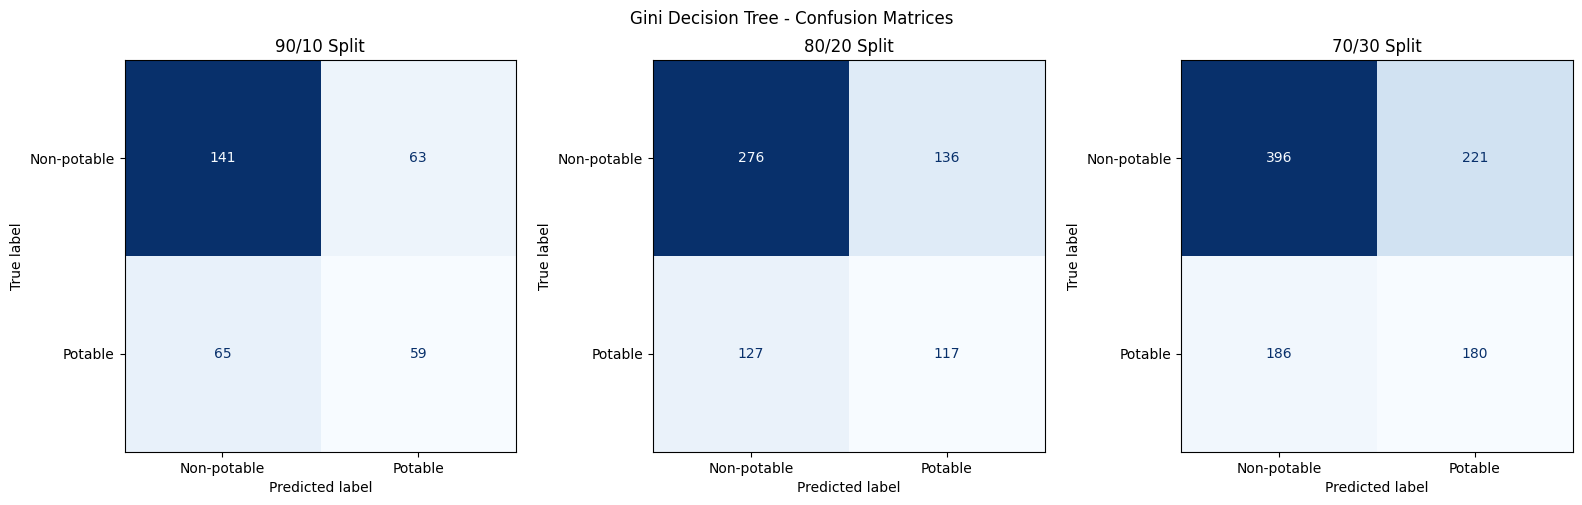

In [ ]:
import numpy as np
confusion_matrices= [
    ("90/10 Split", [[141, 63], [65, 59]]),
    ("80/20 Split", [[276, 136], [127, 117]]),
    ("70/30 Split", [[396, 221], [186, 180]])]

fig, axes= plt.subplots(1, 3, figsize=(16, 5))

for ax, (title, cm) in zip(axes, confusion_matrices):

    disp= ConfusionMatrixDisplay(
        confusion_matrix=np.array(cm),
        display_labels=["Non-potable", "Potable"] )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False)

    ax.set_title(title)

plt.suptitle("Gini Decision Tree - Confusion Matrices")
plt.tight_layout()
plt.show()

The confusion matrices compare the Gini Decision Tree’s classification results across the three data splits (90/10, 80/20, and 70/30), showing correct and incorrect predictions for each class.

### Gini Decision Tree - First 3 Levels (80/20 Split)

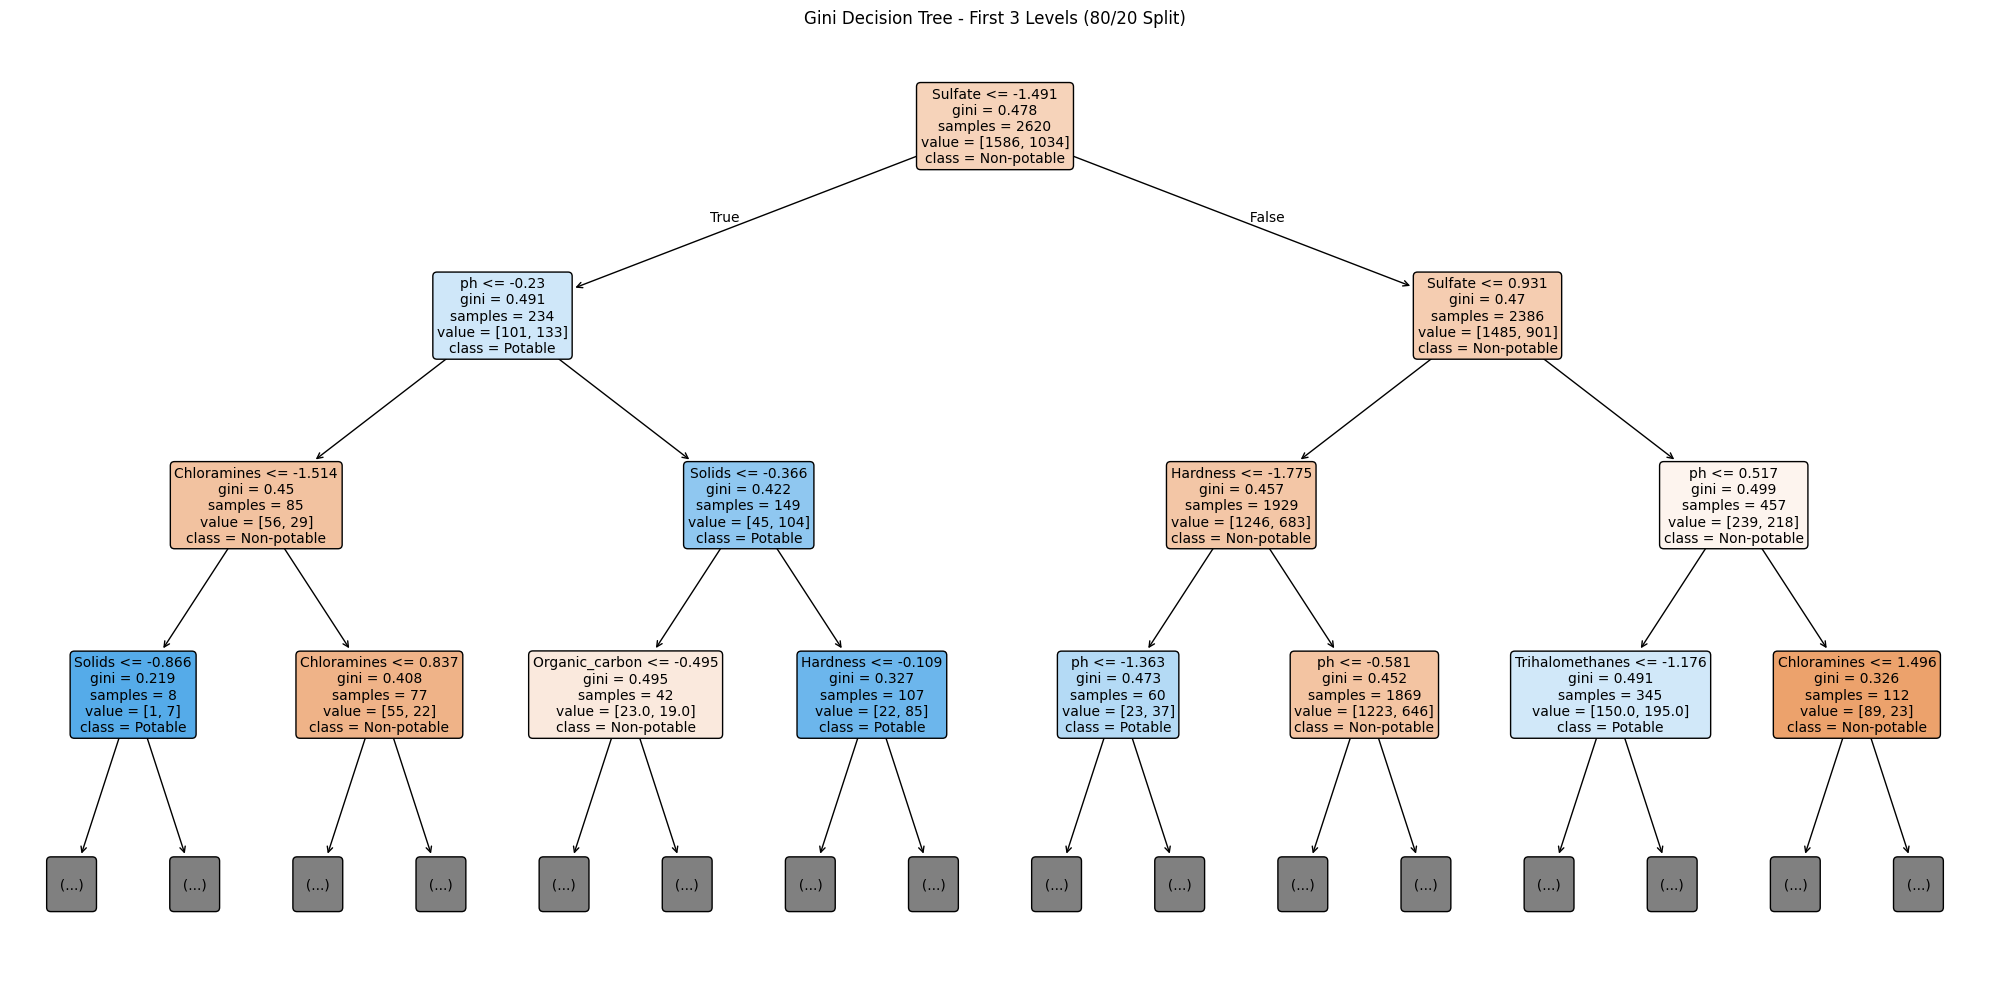

In [ ]:
X_train, X_test, y_train, y_test= train_test_split(
    X, y,
    test_size=0.2,
    random_state=42)

model= DecisionTreeClassifier(
    criterion="gini",
    random_state=42)

model.fit(X_train, y_train)


#Display the top levels of the Gini Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Non-potable", "Potable"],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3)

plt.title("Gini Decision Tree - First 3 Levels (80/20 Split)")
plt.tight_layout()
plt.show()

The decision tree illustrates how the Gini model classifies water samples based on water quality features using the 80/20 split. The first three levels are shown for clarity.

**The Gini Decision Tree achieved its highest accuracy with the 90/10 split (60.98%). Its performance will be compared with the Entropy-based Decision Tree to identify the best model for our dataset.**


### 6.1.2 Decision Tree using Entropy (Information Gain)

### Entropy Decision Tree - 70/30 Partition

In [ ]:
#Split the data: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
#Create the Entropy Decision Tree
model = DecisionTreeClassifier(
    criterion="entropy", random_state=42)
#Train the model
model.fit(X_train, y_train)
#Predict the test data
y_pred = model.predict(X_test)
#Evaluate the model
print("Entropy Decision Tree - 70/30 Split")
print("Accuracy:", accuracy_score(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Actual Non-potable", "Actual Potable"],
    columns=["Predicted Non-potable", "Predicted Potable"]))

Entropy Decision Tree - 70/30 Split
Accuracy: 0.5798575788402849


,Predicted Non-potable,Predicted Potable
Actual Non-potable,401,216
Actual Potable,197,169


With the 70/30 split, the Entropy tree got an accuracy of 57.99%.
Out of 983 test samples, 570 were classified correctly and 413 were wrong. 216 non-potable samples were predicted as potable, and 197 potable samples were predicted as non-potable.The model predicted non-potable samples better than potable ones.

### Entropy Decision Tree - 80/20 Partition

In [ ]:
#Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

#Create the Entropy Decision Tree
model = DecisionTreeClassifier(
    criterion="entropy", random_state=42)

#Train the model
model.fit(X_train, y_train)

#Predict the test data
y_pred = model.predict(X_test)

#Evaluate the model
print("Entropy Decision Tree - 80/20 Split")
print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Actual Non-potable", "Actual Potable"],
    columns=["Predicted Non-potable", "Predicted Potable"]))

Entropy Decision Tree - 80/20 Split
Accuracy: 0.5975609756097561


,Predicted Non-potable,Predicted Potable
Actual Non-potable,273,139
Actual Potable,125,119


For the 80/20 split the accuracy went up a little to 59.76%. The tree got 392 samples right and 264 wrong from the 656 test samples. Most of the mistakes were non-potable water being labeled as potable (139), while 125 potable samples were labeled as non-potable.

### Entropy Decision Tree - 90/10 Partition

In [ ]:
#Split the data: 90% training, 10% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42)

#Create the Entropy Decision Tree
model = DecisionTreeClassifier(
    criterion="entropy", random_state=42)

#Train the model
model.fit(X_train, y_train)

#Predict the test data
y_pred = model.predict(X_test)

#Evaluate the model
print("Entropy Decision Tree - 90/10 Split")
print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Actual Non-potable", "Actual Potable"],
    columns=["Predicted Non-potable", "Predicted Potable"]))

Entropy Decision Tree - 90/10 Split
Accuracy: 0.5670731707317073


,Predicted Non-potable,Predicted Potable
Actual Non-potable,133,71
Actual Potable,71,53


Using 90% of the data for training gave the lowest accuracy for the Entropy tree, only 56.71%. From 328 test samples, 186 were correct and 142 were not. The errors were split evenly, 71 in each direction.

### Entropy Decision Tree - Accuracy Comparison

In [ ]:
#Create a table with the accuracy of each split
entropy_comparison = pd.DataFrame({
    "Train/Test Split": ["90/10", "80/20", "70/30"],
    "Accuracy (%)": [56.7073, 59.7561, 57.9858]
})

#Display the table and highlight the highest accuracy
display(
    entropy_comparison.style
    .format({"Accuracy (%)": "{:.2f}%"})
    .highlight_max(subset=["Accuracy (%)"], color="green")
    .set_caption("Entropy Decision Tree - Accuracy Comparison")
)

,Train/Test Split,Accuracy (%)
0,90/10,56.71%
1,80/20,59.76%
2,70/30,57.99%


The table shows that the 80/20 split had the highest accuracy (59.76%), then 70/30 (57.99%), and 90/10 had the lowest (56.71%). The 90/10 split used more data for training but still got a lower accuracy, because it has fewer test samples so each mistake affects the result more. The accuracies are close to each other, so the split size did not make a big difference.

### Entropy Decision Tree - Colored Confusion Matrices

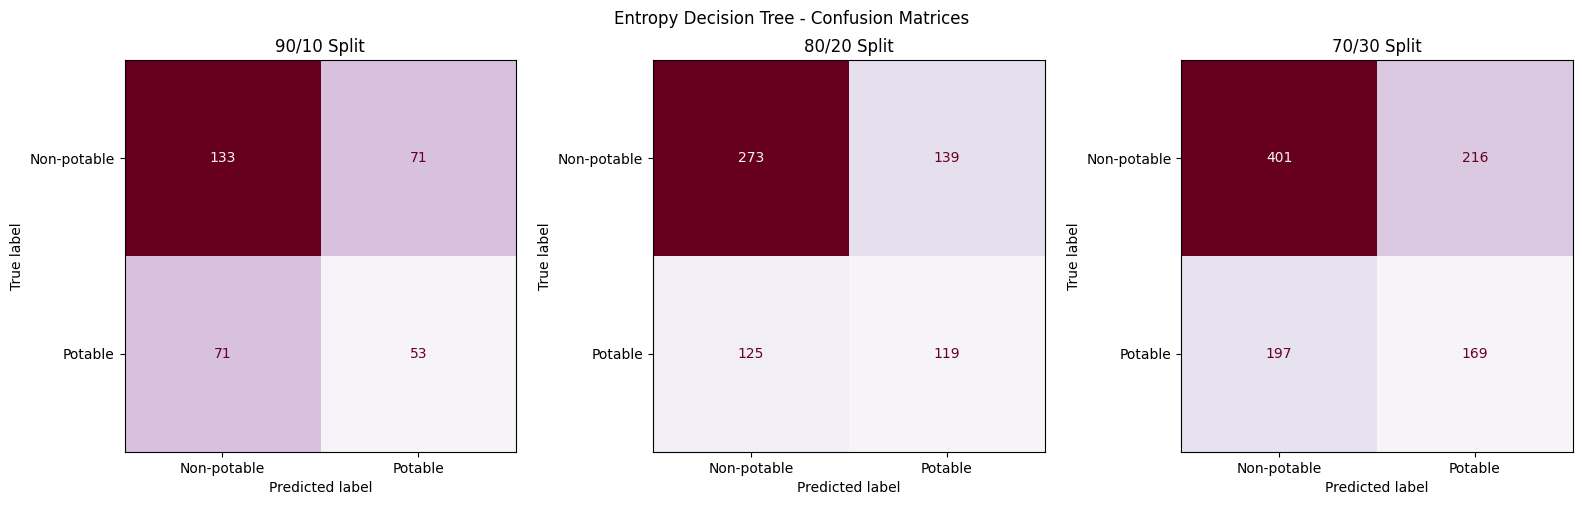

In [ ]:
import numpy as np

#Confusion matrices of the Entropy tree for each split
entropy_confusion_matrices = [
    ("90/10 Split", [[133, 71], [71, 53]]),
    ("80/20 Split", [[273, 139], [125, 119]]),
    ("70/30 Split", [[401, 216], [197, 169]])]

#Create 3 plots next to each other
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

#Draw each confusion matrix
for ax, (title, cm) in zip(axes, entropy_confusion_matrices):

    disp = ConfusionMatrixDisplay(
        confusion_matrix=np.array(cm),
        display_labels=["Non-potable", "Potable"])

    disp.plot(
        ax=ax,
        cmap="PuRd",
        values_format="d",
        colorbar=False)

    ax.set_title(title)

plt.suptitle("Entropy Decision Tree - Confusion Matrices")
plt.tight_layout()
plt.show()

The confusion matrices show the results of the Entropy tree for the three splits. In all of them, the darker cell is the top-left one, which means the model was better at predicting non-potable samples. For potable samples, the number of wrong predictions was higher than the correct ones.

### 6.1.3 Comparison between Gini and Entropy

In [ ]:
#Combine the Gini and Entropy results in one table
comparison = pd.DataFrame({
    "Train/Test Split": ["90/10", "80/20", "70/30"],
    "Gini Accuracy (%)": gini_comparison["Accuracy (%)"].values,
    "Entropy Accuracy (%)": entropy_comparison["Accuracy (%)"].values
})

#Find the better measure for each split
comparison["Better Measure"] = np.where(
    comparison["Gini Accuracy (%)"] > comparison["Entropy Accuracy (%)"], "Gini", "Entropy")

#Display the table
display(
    comparison.style
    .format({"Gini Accuracy (%)": "{:.2f}%", "Entropy Accuracy (%)": "{:.2f}%"})
    .set_caption("Gini vs Entropy - Accuracy Comparison")
)

#Print the average accuracy of each measure
print("Average Gini accuracy:", round(comparison["Gini Accuracy (%)"].mean(), 2), "%")
print("Average Entropy accuracy:", round(comparison["Entropy Accuracy (%)"].mean(), 2), "%")

,Train/Test Split,Gini Accuracy (%),Entropy Accuracy (%),Better Measure
0,90/10,60.98%,56.71%,Gini
1,80/20,59.91%,59.76%,Gini
2,70/30,58.60%,57.99%,Gini


Average Gini accuracy: 59.83 %
Average Entropy accuracy: 58.15 %


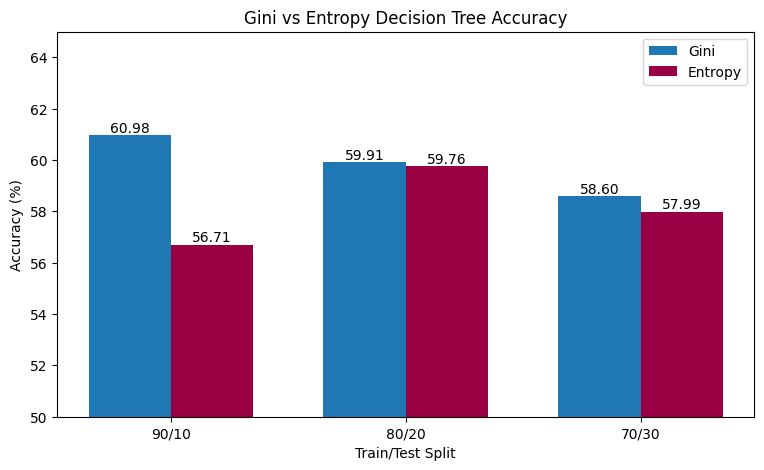

In [ ]:
#Plot the accuracy of Gini and Entropy for each split
x = np.arange(len(comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, comparison["Gini Accuracy (%)"], width, label="Gini", color="tab:blue")
bars2 = ax.bar(x + width/2, comparison["Entropy Accuracy (%)"], width, label="Entropy", color="#980043")

#Show the accuracy value on top of each bar
ax.bar_label(bars1, fmt="%.2f")
ax.bar_label(bars2, fmt="%.2f")

ax.set_xticks(x)
ax.set_xticklabels(comparison["Train/Test Split"])
ax.set_ylim(50, 65)
ax.set_xlabel("Train/Test Split")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Gini vs Entropy Decision Tree Accuracy")
ax.legend()
plt.show()

Gini performed better than Entropy in all three splits. The biggest difference was in the 90/10 split (60.98% vs 56.71%), while in the 80/20 split the two were almost the same (59.91% vs 59.76%). On average, Gini reached 59.83% and Entropy 58.15%, so Gini is the better measure overall for our dataset, and the best model is the Gini tree with the 90/10 split.

However, the accuracies (56.71%-60.98%) were close to the majority class proportion (61%), suggesting limited predictive performance compared to a simple majority-class baseline.

## 6.2 Clustering

### 6.2.1 K-means Clustering
K-Means is an unsupervised learning algorithm that groups similar data points into K clusters.<br>
Three values (K = 2, 3, and 4) were selected to compare different clustering structures, starting from the smallest number of groups and increasing gradually.<br>
The Potability attribute was excluded from clustering because it represents the class label.<br>
Performance is evaluated using the Silhouette Score and Within-Cluster Sum of Squares (WCSS).


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### 6.2.2 K-means Clustering - Evaluation Metrics

In [ ]:
k_values = [2, 3, 4]
silhouette_scores = []
wcss_values = []
cluster_results = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = model.fit_predict(X)
    cluster_results[k] = cluster_labels
    silhouette = silhouette_score(X, cluster_labels)
    wcss = model.inertia_

    silhouette_scores.append(silhouette)
    wcss_values.append(wcss)

    print("K =", k)
    print("Silhouette Score:", round(silhouette, 4))
    print("WCSS:", round(wcss, 2))
    print("-" * 40)

K = 2
Silhouette Score: 0.0828
WCSS: 27019.36
----------------------------------------
K = 3
Silhouette Score: 0.0769
WCSS: 25310.15
----------------------------------------
K = 4
Silhouette Score: 0.0735
WCSS: 24102.41
----------------------------------------


### 6.2.3 K-means Clustering - Metrics Comparison

In [ ]:
kmeans_comparison = pd.DataFrame({
    "K": k_values,
    "Silhouette Score": silhouette_scores,
    "WCSS": wcss_values
})

display(
    kmeans_comparison.style
    .format({
        "Silhouette Score": "{:.4f}",
        "WCSS": "{:.2f}"
    })
    .highlight_max(subset=["Silhouette Score"], color="green")
    .set_caption("K-Means - Metrics Comparison")
)

,K,Silhouette Score,WCSS
0,2,0.0828,27019.36
1,3,0.0769,25310.15
2,4,0.0735,24102.41


K=2 achieved the highest Silhouette Score (0.0828), indicating the best relative cluster separation among the tested values. Its WCSS was 27,019.36.

K=3 achieved a lower Silhouette Score (0.0769), indicating weaker separation than K=2. Its WCSS decreased to 25,310.15, a reduction of about 6.3%.

K=4 had the lowest Silhouette Score (0.0735), indicating the weakest separation among the tested values. Its WCSS decreased further to 24,102.41, a reduction of about 4.8%.

WCSS measures cluster compactness, and it always decreases as K increases, because more clusters mean smaller groups. The lower WCSS at K=3 and K=4 therefore does not show better clustering. The Silhouette Score, which accounts for both cohesion and separation, decreases as K increases, so it is the metric used to compare the three values. All Silhouette Scores were close to zero, indicating weak cluster separation for every K.

### 6.2.4 K-means Clustering - Elbow Method
The Elbow Method is used to evaluate the appropriate number of clusters by plotting WCSS against different K values. The point where the decrease in WCSS begins to slow down indicates a potential optimal number of clusters.

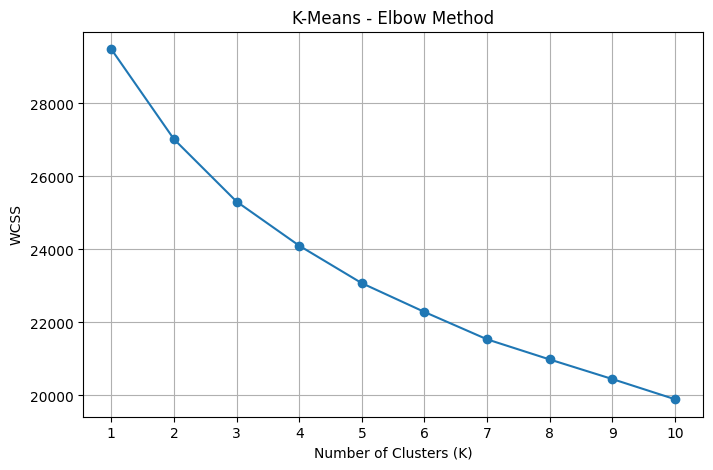

In [ ]:
elbow_k_values = range(1, 11)
elbow_wcss = []

for k in elbow_k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)

    elbow_wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(elbow_k_values, elbow_wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("K-Means - Elbow Method")
plt.xticks(elbow_k_values)
plt.grid(True)
plt.show()

The Elbow Method shows that WCSS decreases as the number of clusters increases, with the largest improvements occurring at lower K values. The curve gradually flattens without a clearly defined elbow, suggesting that no single optimal K can be confidently identified using WCSS alone.

### 6.2.5 K-means Clustering - Visualization

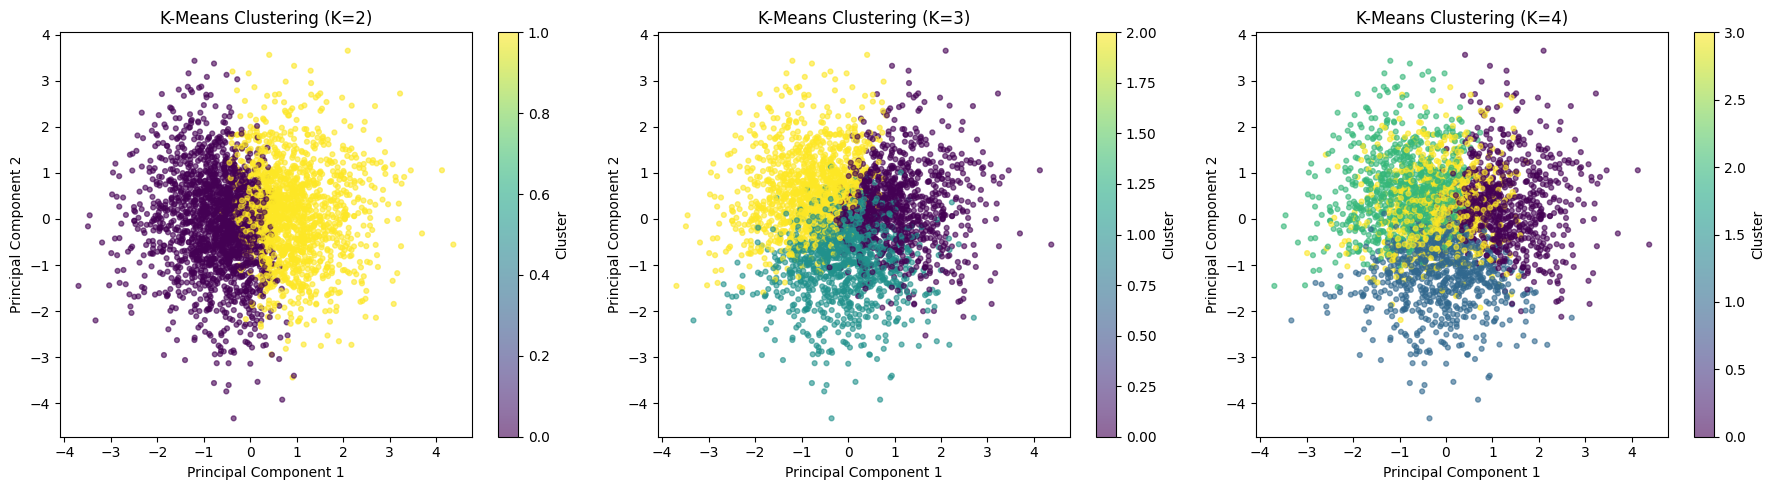

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, k in zip(axes, [2, 3, 4]):
    labels = cluster_results[k]

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=12,
        alpha=0.6
    )

    ax.set_title(f"K-Means Clustering (K={k})")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

    fig.colorbar(scatter, ax=ax, label="Cluster")

plt.tight_layout()
plt.show()

The best K was chosen by majority rule across three criteria:


*   Silhouette Score: favors K=2 (0.0828, compared with 0.0769 and 0.0735).
*   Elbow Method: inconclusive, since the WCSS curve flattens gradually without a clear elbow, so it does not favor any K.
* PCA visualization: favors K=2, which shows the clearest separation, while the clusters for K=3 and K=4 overlap heavily.

Two of the three criteria support K=2 and none supports another value, so K=2 is the best K among those tested. However, the low Silhouette Score shows that even this clustering is weak, and the clusters are not strongly separated.

### 6.2.6 Cluster Interpretation

In [ ]:
cluster_analysis = X.copy()
cluster_analysis["Cluster"] = cluster_results[2]

cluster_means = cluster_analysis.groupby("Cluster").mean()

display(cluster_means.round(3))

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
Cluster,,,,,,,,,
0,0.227,0.069,-0.558,0.202,0.387,-0.102,-0.109,0.100,-0.139
1,-0.280,-0.085,0.688,-0.249,-0.478,0.126,0.134,-0.123,0.172


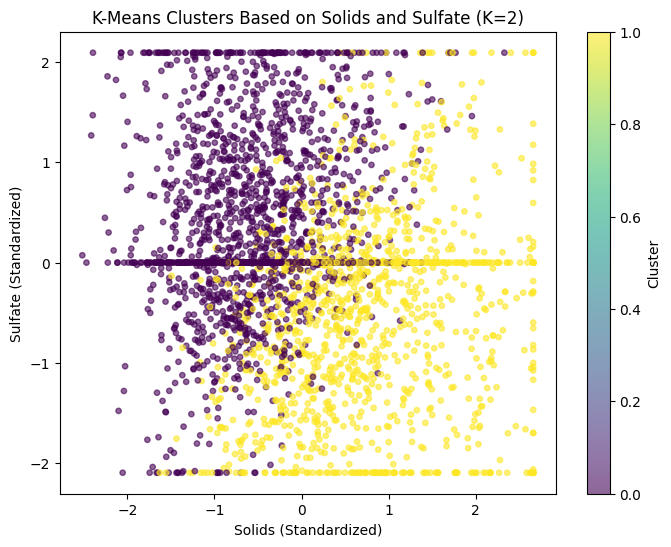

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_analysis["Solids"],
    cluster_analysis["Sulfate"],
    c=cluster_analysis["Cluster"],
    cmap="viridis",
    s=15,
    alpha=0.6
)

plt.xlabel("Solids (Standardized)")
plt.ylabel("Sulfate (Standardized)")
plt.title("K-Means Clusters Based on Solids and Sulfate (K=2)")
plt.colorbar(label="Cluster")
plt.show()

To better understand the clustering results for K=2, the mean values of the water quality features were calculated for each cluster. The results show that Cluster 0 has lower average Solids (-0.558) and higher average Sulfate (0.387), while Cluster 1 has higher average Solids (0.688) and lower average Sulfate (-0.478).

The scatter plot supports these differences, as Cluster 0 is mainly concentrated toward lower Solids values and Cluster 1 toward higher Solids values. However, the two clusters overlap considerably, indicating that these features alone do not clearly separate all water samples.

Since the features were standardized, the reported values represent differences relative to the dataset averages rather than the original measurement units.

# [7] Findings and Discussion

The Decision Tree results showed that Gini performed better than Entropy across all three train/test splits. The highest accuracy was 60.98% using Gini with the 90/10 split. However, the overall accuracy values were relatively low, indicating limited performance in predicting water potability.

The final decision tree helps explain how the classification is achieved. Only the first three levels are shown for clarity. The root node splits on Sulfate, so it is the first attribute the model uses to separate the samples. The next levels split on ph and Sulfate again, followed by Chloramines, Solids and Hardness. This shows that potability is decided by a combination of several attributes rather than one single attribute, and no single attribute clearly separates potable from non-potable water, which explains the limited accuracy.

For K-Means clustering, K=2 was selected as the best K by majority rule: it had the highest Silhouette Score (0.0828), it showed the clearest separation in the PCA plot, and the Elbow Method did not favor any other value. The Elbow Method showed a gradual decrease in WCSS without a clearly defined elbow, making it difficult to identify a single optimal K. The clusters showed differences in Solids and Sulfate, but the visualizations revealed considerable overlap, indicating weak separation between water samples.

Rahmawati et al. [1] evaluated KNN and Naïve Bayes using the same water potability dataset and reported accuracies of 65% and 64%, respectively. These results were higher than our best Decision Tree accuracy of 60.98%. However, their study used different algorithms and applied oversampling, so the results are not directly comparable. Overall, our findings suggest that predicting water potability remains challenging, while K-Means also showed weak separation between water samples.


# [8] References

[1] A. Rahmawati, M. Fatchan, and W. Hadikristanto, "Valuation K-nearest neighbors and Naïve Bayes for Dringking [sic] water potability classification," *Int. J. Sustain. Appl. Sci.*, vol. 2, no. 5, pp. 511–522, 2024, doi: 10.59890/ijsas.v2i5.1864.

[2] uom190346a, "Water quality and potability," Kaggle. Accessed: Nov. 7, 2026. [Online]. Available: https://www.kaggle.com/datasets/uom190346a/water-quality-and-potability

[3] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.